In [1]:
r_path <- "/notebooks/Bioinformatics/lib/"
.libPaths(c(r_path, .libPaths()))
if (!require("BiocManager", quietly = TRUE)) {
    install.packages("BiocManager", lib=r_path, force=TRUE)
    }
BiocManager::install("PRROC", lib=r_path, force=TRUE)

# Load required packages
library(ape)        # For reading GenBank files
library(Biostrings) # For sequence manipulation
library(HMM)        # For building simple HMMs
library(msa)        # For performing multiple sequence alignment
library(aphid)      # For building profile HMMs
library(igraph)     # For graph analysis
library(PRROC)      # For computing precision-recall curves and associated metrics


Bioconductor version '3.21' is out-of-date; the current release version '3.22'
  is available with R version '4.5'; see https://bioconductor.org/install

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cloud.r-project.org

Bioconductor version 3.21 (BiocManager 1.30.26), R 4.5.1 (2025-06-13)

Installing package(s) 'PRROC'

Old packages: 'aphid', 'kmer'

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, 

In [2]:
# Read sequences, Hint: readAAStringSet
seq1 <- readAAStringSet("../data/ex2/NP_001001957.2.faa")
seq2 <- readAAStringSet("../data/ex2/NP_149420.4.faa")
seq3 <- readAAStringSet("../data/ex2/WLF82657.1.faa")

AAStringSet object of length 1:
    width seq                                               names               
[1]   314 MDGTNGSTQTHFILLGFSDRPHL...LRNREVKGALGRLLLGKRELGKE NP_001001957.2 ol...

In [3]:
# PART 1: Viterbi decoding---------------

# Define transition matrix
T <- matrix(c(0.8, 0.2, 0.05, 0.95), byrow=TRUE, 
            nrow=2, ncol=2, 
            dimnames=list(c("IN", "OUT"), c("IN", "OUT")))

# Define emission frequency matrix
in_freqs <- c(15, 11, 10, 9, 12, 8, 4, 12, 8, 29, 36, 8, 13, 24, 15, 34, 20, 1, 12, 31)
out_freqs <- c(10, 16, 12, 5, 17, 18, 4, 12, 11, 20, 45, 12, 17, 20, 19, 26, 20, 7, 6, 15)
aa_symbols <- c("A", "R", "N", "D", "C", "Q", "E", "G", "H", "I", "L", "K", "M", "F", "P", "S", "T", "W", "Y", "V")

F <- matrix(c(in_freqs, out_freqs), byrow = TRUE, 
            nrow = 2, ncol = length(aa_symbols), 
            dimnames=list(c("IN", "OUT"), aa_symbols))

# Convert F to an emission probability matrix, E
E <- F/rowSums(F) #Hint: colSums or rowSums()

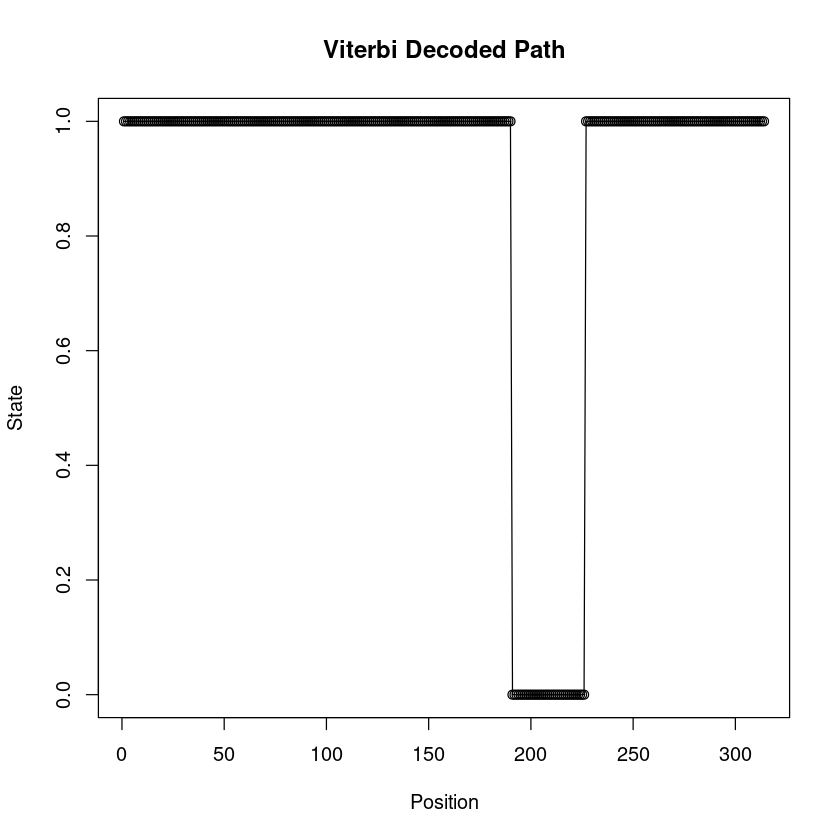

In [9]:
# 1. Viterbi decoding algorithm from scratch
viterbi_decoding <- function(s, T, E, K){
	# Transform T and E to their log2 equivalents
	logT <- log2(T)
    logE <- log2(E)

	n <-  length(s) # sequence length

	# Initialize viterbi and pointer matrices
	V <- matrix(-Inf, byrow = TRUE, 
            nrow = K, ncol = n + 1, 
            dimnames=list(c("IN", "OUT"), NULL)) # of dimension: Num(states) x (n+1)
	P <- matrix(NA, byrow = TRUE, 
            nrow = K, ncol = n, 
            dimnames=list(c("IN", "OUT"), NULL)) # of dimension: Num(states) x (n)

	# initialize the first column of V
	V[,1] <- log2(0.5)

	for (i in 2:(n+1)){
		for (l in 1:K){
			# populate V and P matrices using the recursive relation
			V[l, i] = max(V[, i-1] + logT[, l]) + logE[l, s[i-1]]          
			P[l, i-1] = which.max(V[, i-1] + logT[, l]) # store best path
		}
	}
    
    # Last state
    last_state = which.max(V[, n+1])
    log_prob = V[last_state, n+1]

	# Use P to trace the most probable path
    path <- numeric(n)
    path[n] <- last_state
    
    for (i in (n - 1):1) {
        path[i] <- P[path[i + 1], i]
    }

	#initialize a list or dictionary to store the results
	result <- list()
	result$V <- V # store viterbi matrix
	result$P <- P # store pointer matrix 
    result$path <- path # probable path
	result$log_prob <- log_prob # log probability of the probable path

	return(result)
}

s <- strsplit(as.character(seq1[[1]]), "")[[1]]
result <- viterbi_decoding(s, T, E, 2) 
path <- result$path

# Piecewise plot Hint: ifelse() to map the states to 0/1
binary_path <- ifelse(path == 1, 0, 1)
# plot(..., type="o", ...)
plot(binary_path, type = "o", ylab = "State", xlab = "Position", main = "Viterbi Decoded Path")

In [5]:
# 2. Sequence scoring via viterbi decoding
for (seq in list(seq1, seq2, seq3)) {
    s_test <- strsplit(as.character(seq[[1]]), "")[[1]]
    print(viterbi_decoding(s_test, T, E, 2 )$log_prob)
}
    

      OUT 
-1338.119 
      OUT 
-1336.655 
      OUT 
-1692.116 


Final transition probability matrix



,IN,OUT
IN,0.972222222,0.02777778
OUT,0.003610108,0.99638989


 Final emmission probability matrix



,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
IN,0.08333333,0.02777778,0.00000000,0.00000000,0.00000000,0.00000000,0.02777778,0.05555556,0.00000000,0.08333333,0.1388889,0.00000000,0.00000000,0.05555556,0.02777778,0.1111111,0.05555556,0.000000000,0.05555556,0.27777778
OUT,0.05035971,0.05755396,0.03597122,0.02877698,0.03597122,0.02877698,0.02517986,0.08273381,0.03597122,0.06115108,0.1690647,0.02158273,0.04676259,0.05035971,0.04316547,0.0647482,0.05755396,0.003597122,0.03956835,0.06115108


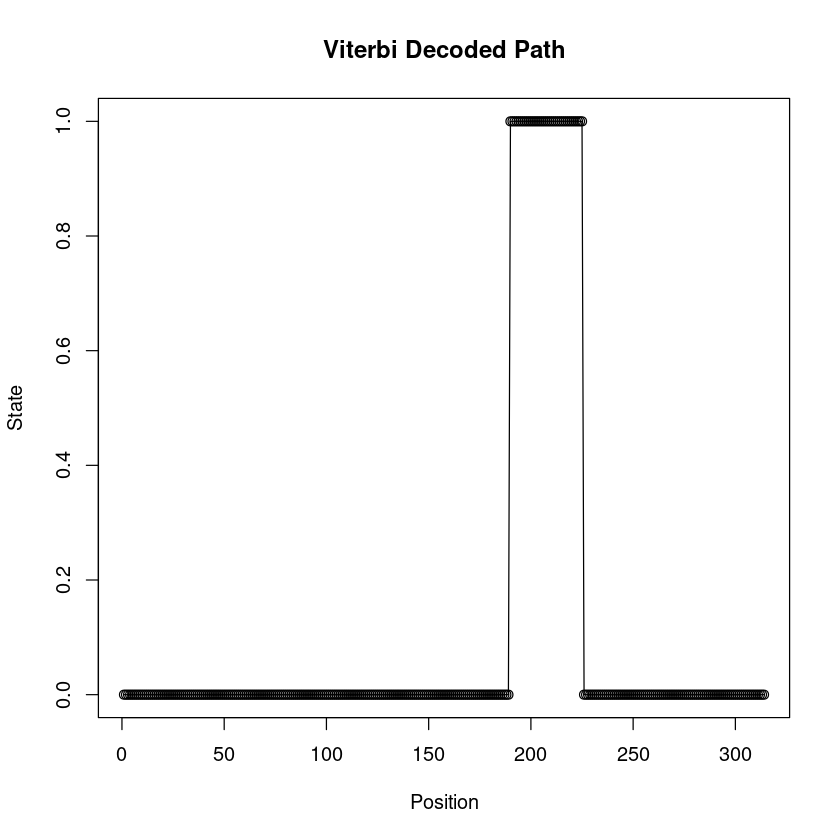

In [10]:
# 3. HMM training

# initialize 2-state HMM
hmm <- initHMM(States=c("IN","OUT"), Symbols=aa_symbols,
	startProbs=c(0.5, 0.5) , transProbs=T, emissionProbs=E)

test_seq1 <- s
trainedHMM <- viterbiTraining(hmm, test_seq1, maxIterations=100, delta = 1e-9)$hmm

# infer most likely hidden state sequence 
viterbi_trained_path <- viterbi(trainedHMM, s) 

message("Final transition probability matrix")
trainedHMM$transProbs

message(" Final emmission probability matrix")
trainedHMM$emissionProbs



# plot hidden state sequence as piecewise
binary_viterbi_trained_path <- ifelse(viterbi_trained_path == "IN", 0, 1)
# plot(..., type="o", ...)
plot(binary_viterbi_trained_path, type = "o", ylab = "State", xlab = "Position", main = "Viterbi Decoded Path")

In [15]:
# PART 2: Probabilistic modeling of protein families with profile HMMs---------------

# Read sequences, Hint: readAAStringSet
protein_family  <- readAAStringSet("../data/ex2/rats_olfactory_receptors.fasta") 

# Compute MSA
msa_result <- msa(protein_family, method="ClustalW")

# plot columns 50-165, Hint: msaPrettyPrint()
msaPrettyPrint(msa_result, y = c(50, 165), output="pdf", file="msa_plot.pdf", showNames = "none")

msa_AAbin <- as.AAbin(msa_result)

# Derive HMM based on given protein family
# convert msa to AAbin (binary data format)
profile_HMM <- derivePHMM(msa_AAbin, residues="AMINO", pseudocount="Laplace", alignment=TRUE,odds = FALSE, logspace = TRUE)


# Score sequences
for (seq in list(seq1, seq2, seq3)) {
    s_test <- strsplit(as.character(seq[[1]]), "")[[1]]
    print(Viterbi(profile_HMM,s_test)$score)
}


use default substitution matrix


Warning message in texi2dvi(texfile, quiet = !verbose, pdf = identical(output, "pdf"), :
“texi2dvi script/program not available, using emulation”


[1] 168.5729
[1] 42.71219
[1] -61.54202


In [16]:
# PART 4: Post-hoc consistency correction of a model’s predictions---------------

# Define graph edges
edges <- c(
	"a", "b", #a->b
	"a", "c",
	"b", "d",
    "b", "e",
    "c", "f",
    "c", "g",
    "c", "h",
    "f", "i",
    "g", "i")

# Create DAG graph, Hint: igraph::make_graph
dag <- igraph::make_graph(edges, directed = TRUE) 

# Enumerate all consistent subgraphs in dag

enumerate_subgraphs <- function(g, root, r){
	# Find all descendants of a given node (root node preferably)
	# Hint: igraph's subcomponent()
    descendants <- subcomponent(g, root, mode = "out")
    desc_names <- V(g)[descendants]$name
    length(descendants)
    
	# initialize list to store consistent subgraphs found
    consistent_subgraphs <- list()
    
	# for each descendant
	for (d in 1:length(desc_names)){
        cur_node <- desc_names[d]
    
        # Get the sub-family of THIS specific descendant
        # This limits the search to the branch starting at 'cur_node'
        local_desc <- subcomponent(g, cur_node, mode = "out")
        local_desc_names <- V(g)[local_desc]$name
        if (length(local_desc_names) < r) next # move on if length doesn't suffice
        
		# enumerate all combinations of nodes (i.e. random subgraphs)
		for (nodes in combn(local_desc_names, r, simplify=FALSE)){
			# generate the subgraph induced by the set of nodes
            if (!(cur_node %in% nodes)) next # move on if local root node was not part of the combinations
			# Hint: igraph's subgraph
            subg <- subgraph(g, nodes)

			# node names can be accessed by: V(g)$name

			# Reflect on what a consistent graph is
			# Check if induced subgraph meets the consistency criteria
            is_consistent <- TRUE
            
            for (node in nodes) {
                all_parents <- neighbors(g, node, mode = "in")$name
    
                # FILTER: We only care about parents who are ALSO in our branch (local_pool)
                # This ignores the Grandparent because they are 'outside' our current study
                required_parents <- intersect(all_parents, local_desc_names)

                # Check if THESE specific parents are in our r-sized team
                if (!all(required_parents %in% nodes)) {
                    is_consistent <- FALSE
                    break
                }
            }

			# store the node set forming the consistent subgraph in the list 
            if (is_consistent) {
                consistent_subgraphs[[length(consistent_subgraphs) + 1]] <- nodes
            } 
		}
	}
	
	return(consistent_subgraphs)
}

all_consistent_subgraphs <- list()
all_descs <- subcomponent(dag, "a", mode = "out")
for (i in 1:length(all_descs)){
    all_consistent_subgraphs[[length(all_consistent_subgraphs) + 1]] <- enumerate_subgraphs(dag, "a", i)   
}


# number of consistent subgraphs
message("Number of consistent subgraphs")
sum(lengths(all_consistent_subgraphs))

# number of subgraphs having 7 nodes
message("Number of subgraphs having 7 nodes")
length(enumerate_subgraphs(dag, "a", 7))

Number of consistent subgraphs



[1] 77

Number of subgraphs having 7 nodes



[1] 8

In [20]:
# Post-hoc consistency correction
consistency_correction <- function(g, dictionary_of_node_scores){
	# Check lecture notes,
	# Useful function: topo_sort(), rev(), neighbors(), max()
    corrected_scores <- dictionary_of_node_scores
    node_ordering <- topo_sort(g)
    for (v in rev(node_ordering)) {
        v <- V(g)[v]$name
        parents <- neighbors(g,v,mode = "in")$name
        for (p in parents) {
            prev_score <- corrected_scores[p]
            corrected_scores[p] <- max(prev_score, corrected_scores[v])
        }    
    }    
	return(corrected_scores)
}

#Thresholding, Hint: sapply(),

ytrue <- c(1, 0, 1, 0, 0, 1, 1, 0, 1); 
yhat_before_correction <- c(
  "a" = 0.55, "b" = 0.32, "c" = 0.95, 
  "d" = 0.7, "e" = 0.49, "f" = 0.23, 
  "g" = 0.63, "h" = 0.85, "i" = 0.4
)
yhat_after_correction <- consistency_correction(dag, yhat_before_correction) 

# Threshold function: 1(y_hat >= 0.5)
threshold <- function(score) {
    return(as.numeric(score >= 0.5))
}

# Apply thresholding
m1_predicted_binary <- sapply(yhat_before_correction, threshold)
m2_predicted_binary <- sapply(yhat_after_correction, threshold)

# Identify nodes in the corrected subgraph
corrected_subgraph_nodes <- names(m2_predicted_binary[m2_predicted_binary == 1])

message("The respective final score for each node, after the correction pro-
cedure")
yhat_after_correction

message("The nodes in the corrected subgraph")
corrected_subgraph_nodes

The respective final score for each node, after the correction pro-
cedure



a    b    c    d    e    f    g    h    i 
0.95 0.70 0.95 0.70 0.49 0.40 0.63 0.85 0.40

The nodes in the corrected subgraph



[1] "a" "b" "c" "d" "g" "h"

Area under the curves (AUC) for Model 1 (before correction)



[1] 0.6089529

Area under the curves (AUC) for Model 2 (after correction)



[1] 0.6895555

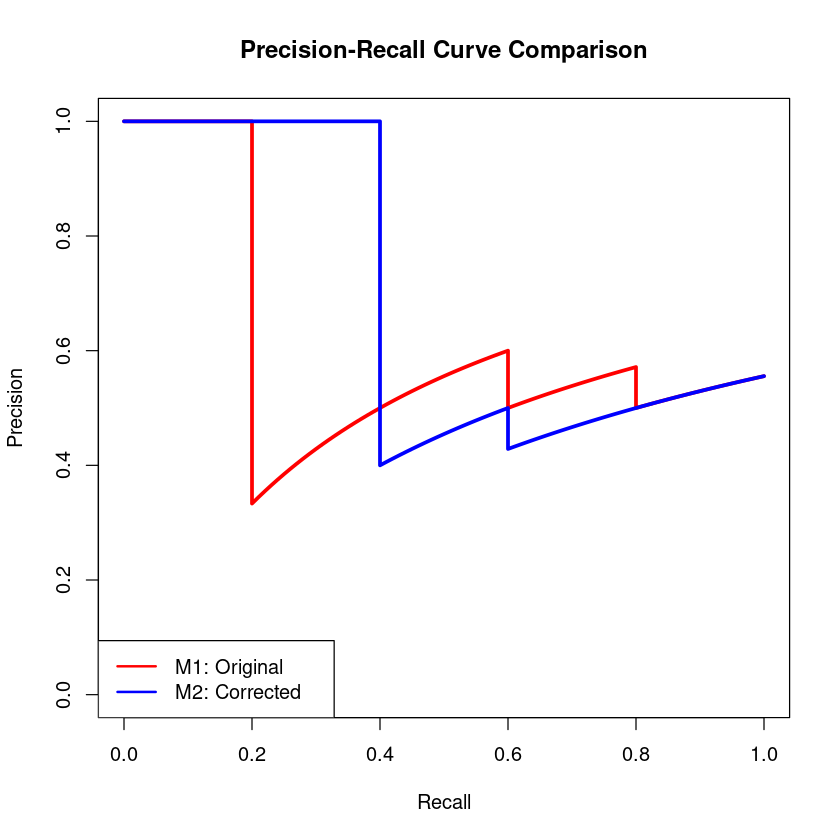

In [22]:

pr_curve1 <- pr.curve(scores.class0 = yhat_before_correction, 
                      weights.class0 = ytrue , 
                      curve = TRUE)

pr_curve2 <- pr.curve(scores.class0 = yhat_after_correction, 
                      weights.class0 = ytrue, 
                      curve = TRUE)

#retrieve AUC values:
auc_before_correction <- pr_curve1$auc.integral 
auc_after_correction <- pr_curve2$auc.integral

message("Area under the curves (AUC) for Model 1 (before correction)")
auc_before_correction

message("Area under the curves (AUC) for Model 2 (after correction)")
auc_after_correction


# Plot M1
plot(pr_curve1, color = "red", main = "Precision-Recall Curve Comparison", auc.main = FALSE,xlab = "Recall", 
     ylab = "Precision")
# Plot M2 on the same graph
plot(pr_curve2, color = "blue", add = TRUE, auc.main = FALSE)

# Add legend
legend("bottomleft", legend = c("M1: Original", "M2: Corrected"), 
       col = c("red", "blue"), lty = 1, lwd = 2)